# Financial sentiment classification benchmark (Kaggle)

Self-contained notebook: upload it to Kaggle and attach the benchmark CSV dataset as an **Input**. It automatically locates the PhraseBank and Twitter CSVs under `/kaggle/input`.

It fine-tunes three finance-domain pretrained encoders independently on each classification dataset: FinBERT, FLANG-RoBERTa, and FLANG-DistilBERT. PhraseBank uses a stratified 80/10/10 split. For Twitter, its supplied `train` split is divided into training and validation data, and the supplied `validation` split is reserved for final testing.

The setup uses AdamW, a short linear warmup/decay schedule, early stopping on validation macro-F1, gradient clipping, mixed precision on CUDA, and a modest regularized MLP head. These settings are a solid starting point rather than a guarantee of a global optimum; compare held-out test metrics and tune only against validation data. Internet must be enabled in Kaggle to download the checkpoints on the first run.

## Dependencies

Run the next cell first. Kaggle generally provides a CUDA-enabled PyTorch installation, which this notebook keeps. If package installation updates an already-imported library, restart the Kaggle session and run from the top.

In [1]:
%pip install -q "transformers<5" sentencepiece numpy pandas scikit-learn matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 104.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 86.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import copy
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer, get_linear_schedule_with_warmup

warnings.filterwarnings("ignore", category=FutureWarning)

# Auto-detect the attached dataset rather than relying on a Kaggle account-specific slug.
INPUT_ROOT = Path("/kaggle/input")

def find_input(filename):
    matches = list(INPUT_ROOT.rglob(filename)) if INPUT_ROOT.exists() else []
    if not matches:
        raise FileNotFoundError(f"Could not find {filename} under {INPUT_ROOT}. Attach the benchmark dataset as a Kaggle Input.")
    return matches[0]

PHRASEBANK_PATH = find_input("financial_phrasebank_50agree.csv")
TWITTER_PATH = find_input("twitter_financial_news_sentiment.csv")
OUTPUT_DIR = Path("/kaggle/working/financial_sentiment_classification")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_CHECKPOINTS = {
    "FinBERT": "yiyanghkust/finbert-pretrain",
    "FLANG-RoBERTa": "SALT-NLP/FLANG-Roberta",
    "FLANG-DistilBERT": "SALT-NLP/FLANG-DistilBERT",
}
LABELS = ["negative", "neutral", "positive"]
LABEL_TO_ID = {name: index for index, name in enumerate(LABELS)}
SEED = 42
MAX_LENGTH = 128
BATCH_SIZE = 16  # Lower to 8 or 4 if your Kaggle GPU runs out of memory.
EPOCHS = 30
ENCODER_LR = 5e-6
HEAD_LR = 1e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
DROPOUT = 0.20
HEAD_HIDDEN_SIZES = (256,)
PATIENCE = 10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

print("Device:", DEVICE)
print("PhraseBank:", PHRASEBANK_PATH)
print("Twitter:", TWITTER_PATH)
print("Model checkpoints:", MODEL_CHECKPOINTS)
print("Kaggle Internet must be enabled for first-time model downloads.")

Device: cuda
PhraseBank: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/financial_phrasebank_dataset/financial_phrasebank_50agree.csv
Twitter: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/twitter_financial_news_sentiment.csv
Model checkpoints: {'FinBERT': 'yiyanghkust/finbert-pretrain', 'FLANG-RoBERTa': 'SALT-NLP/FLANG-Roberta', 'FLANG-DistilBERT': 'SALT-NLP/FLANG-DistilBERT'}
Kaggle Internet must be enabled for first-time model downloads.


In [3]:
import torch
from torch import nn
from transformers import AutoModel

class ClassificationHead(nn.Module):
    def __init__(self, hidden_size, num_labels, dropout=0.2, hidden_sizes=(256,)):
        super().__init__()
        layers, input_size = [], hidden_size
        for width in hidden_sizes:
            layers.extend([nn.Linear(input_size, width), nn.LayerNorm(width), nn.GELU(), nn.Dropout(dropout)])
            input_size = width
        layers.append(nn.Linear(input_size, num_labels))
        self.network = nn.Sequential(*layers)

    def forward(self, pooled):
        return self.network(pooled)

class RegressionHead(nn.Module):
    def __init__(self, hidden_size, dropout=0.2, hidden_sizes=(256,)):
        super().__init__()
        layers, input_size = [], hidden_size
        for width in hidden_sizes:
            layers.extend([nn.Linear(input_size, width), nn.LayerNorm(width), nn.GELU(), nn.Dropout(dropout)])
            input_size = width
        layers.append(nn.Linear(input_size, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, pooled):
        return self.network(pooled).squeeze(-1)

class FinancialTransformerBase(nn.Module):
    """Shared encoder composition; subclasses attach a task-specific head."""
    def __init__(self, checkpoint, task_head, **model_kwargs):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(checkpoint, **model_kwargs)
        config = self.encoder.config
        hidden_size = getattr(config, "hidden_size", None) or getattr(config, "dim", None) or getattr(config, "d_model", None)
        if hidden_size is None:
            raise ValueError(f"Could not find encoder hidden size for {checkpoint}")
        self.head = task_head(int(hidden_size))

    def pooled_output(self, input_ids, attention_mask, token_type_ids=None):
        inputs = {"input_ids": input_ids, "attention_mask": attention_mask}
        if token_type_ids is not None:
            inputs["token_type_ids"] = token_type_ids
        output = self.encoder(**inputs)
        pooled = getattr(output, "pooler_output", None)
        return pooled if pooled is not None else output.last_hidden_state[:, 0]

class FinancialTextClassifier(FinancialTransformerBase):
    def __init__(self, checkpoint, num_labels=3, dropout=0.2, hidden_sizes=(256,)):
        super().__init__(checkpoint, lambda size: ClassificationHead(size, num_labels, dropout, hidden_sizes))

    def forward(self, input_ids, attention_mask, token_type_ids=None):
        return self.head(self.pooled_output(input_ids, attention_mask, token_type_ids))

class FinancialTextRegressor(FinancialTransformerBase):
    def __init__(self, checkpoint, dropout=0.2, hidden_sizes=(256,)):
        super().__init__(checkpoint, lambda size: RegressionHead(size, dropout, hidden_sizes))

    def forward(self, input_ids, attention_mask, token_type_ids=None):
        return self.head(self.pooled_output(input_ids, attention_mask, token_type_ids))

In [4]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def load_dataset_splits(dataset_name):
    if dataset_name == "Financial PhraseBank":
        frame = pd.read_csv(PHRASEBANK_PATH).dropna(subset=["text", "label"]).copy()
        frame["label"] = frame["label"].str.lower().map(LABEL_TO_ID)
        frame = frame.dropna(subset=["label"])
        frame["label"] = frame["label"].astype(int)
        train, remainder = train_test_split(frame, test_size=0.20, random_state=SEED, stratify=frame["label"])
        validation, test = train_test_split(remainder, test_size=0.50, random_state=SEED, stratify=remainder["label"])
    elif dataset_name == "Twitter Financial News Sentiment":
        frame = pd.read_csv(TWITTER_PATH).dropna(subset=["text", "label", "split"]).copy()
        mapping = {"bearish": "negative", "neutral": "neutral", "bullish": "positive"}
        frame["label"] = frame["label"].str.lower().map(mapping).map(LABEL_TO_ID)
        frame = frame.dropna(subset=["label"])
        frame["label"] = frame["label"].astype(int)
        source_train = frame[frame["split"].str.lower() == "train"].copy()
        test = frame[frame["split"].str.lower() == "validation"].copy()
        train, validation = train_test_split(source_train, test_size=0.10, random_state=SEED, stratify=source_train["label"])
    else:
        raise ValueError(dataset_name)
    return tuple(part.reset_index(drop=True) for part in (train, validation, test))


class SentimentDataset(Dataset):
    def __init__(self, frame, tokenizer):
        self.texts = frame["text"].astype(str).tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.tokenizer = tokenizer
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        item = self.tokenizer(self.texts[index], truncation=True, max_length=MAX_LENGTH, padding=False)
        item["labels"] = self.labels[index]
        return item


def collator_for(tokenizer):
    def collate(items):
        labels = torch.tensor([item.pop("labels") for item in items], dtype=torch.long)
        batch = tokenizer.pad(items, padding=True, return_tensors="pt")
        batch["labels"] = labels
        return batch
    return collate


def make_loader(frame, tokenizer, shuffle=False):
    return DataLoader(SentimentDataset(frame, tokenizer), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=0, pin_memory=DEVICE.type == "cuda", collate_fn=collator_for(tokenizer))


def metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
    }


def predict(model, loader):
    model.eval()
    actual, predicted = [], []
    with torch.no_grad():
        for batch in loader:
            labels = batch.pop("labels")
            batch = {key: value.to(DEVICE, non_blocking=True) for key, value in batch.items()}
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = model(**batch)
            actual.extend(labels.tolist())
            predicted.extend(logits.argmax(dim=-1).cpu().tolist())
    return np.asarray(actual), np.asarray(predicted)

In [5]:
def train_one_model(dataset_name, model_label, checkpoint):
    set_seed()
    train_frame, val_frame, test_frame = load_dataset_splits(dataset_name)
    print(f"Loading tokenizer for {model_label}: {checkpoint}")
    tokenizer = AutoTokenizer.from_pretrained(checkpoint, use_fast=False)
    train_loader = make_loader(train_frame, tokenizer, shuffle=True)
    val_loader = make_loader(val_frame, tokenizer)
    test_loader = make_loader(test_frame, tokenizer)

    model = FinancialTextClassifier(checkpoint, len(LABELS), DROPOUT, HEAD_HIDDEN_SIZES).to(DEVICE)
    # Mild inverse-frequency weighting supports macro-F1 without extreme minority-class weights.
    counts = np.bincount(train_frame["label"].to_numpy(), minlength=len(LABELS))
    class_weights = torch.tensor(np.sqrt(counts.sum() / (len(LABELS) * np.maximum(counts, 1))), dtype=torch.float32)
    class_weights = class_weights / class_weights.mean()
    loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))

    head_params = list(model.head.parameters())
    head_ids = {id(param) for param in head_params}
    encoder_params = [param for param in model.parameters() if id(param) not in head_ids]
    optimizer = torch.optim.AdamW([
        {"params": encoder_params, "lr": ENCODER_LR},
        {"params": head_params, "lr": HEAD_LR},
    ], weight_decay=WEIGHT_DECAY)
    total_steps = max(1, len(train_loader) * EPOCHS)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * WARMUP_RATIO), total_steps)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    best_f1, best_state, stale, history = -1.0, None, 0, []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum, seen = 0.0, 0
        for batch in train_loader:
            labels = batch.pop("labels").to(DEVICE, non_blocking=True)
            batch = {key: value.to(DEVICE, non_blocking=True) for key, value in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = model(**batch)
                loss = loss_fn(logits, labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            loss_sum += loss.item() * labels.size(0)
            seen += labels.size(0)

        y_val, p_val = predict(model, val_loader)
        val_metrics = metrics(y_val, p_val)
        row = {"epoch": epoch, "train_loss": loss_sum / max(seen, 1), **{f"val_{k}": v for k, v in val_metrics.items()}}
        history.append(row)
        print(f"{model_label} | {dataset_name} | epoch {epoch}: loss={row['train_loss']:.4f}, val_macro_f1={val_metrics['macro_f1']:.4f}")
        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
            if stale >= PATIENCE:
                print("Early stopping: validation macro-F1 did not improve.")
                break

    model.load_state_dict(best_state)
    y_test, p_test = predict(model, test_loader)
    result = {"dataset": dataset_name, "model": model_label, "checkpoint": checkpoint,
              "train_rows": len(train_frame), "validation_rows": len(val_frame), "test_rows": len(test_frame),
              **metrics(y_test, p_test)}
    class_report = classification_report(y_test, p_test, labels=list(range(len(LABELS))),
                                         target_names=LABELS, output_dict=True, zero_division=0)
    if SAVE_CHECKPOINTS:
        torch.save(best_state, OUTPUT_DIR / f"{dataset_name.lower().replace(' ', '_')}_{model_label.lower().replace('-', '_')}.pt")
    del model, optimizer, scheduler
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result, pd.DataFrame(history), y_test, p_test, class_report

SAVE_CHECKPOINTS = False
all_results, all_histories, all_predictions, all_reports = [], {}, {}, {}
for dataset_name in ["Financial PhraseBank", "Twitter Financial News Sentiment"]:
    for model_label, checkpoint in MODEL_CHECKPOINTS.items():
        result, history, y_test, p_test, report = train_one_model(dataset_name, model_label, checkpoint)
        all_results.append(result)
        all_histories[(dataset_name, model_label)] = history
        all_predictions[(dataset_name, model_label)] = (y_test, p_test)
        all_reports[(dataset_name, model_label)] = report

results_df = pd.DataFrame(all_results).sort_values(["dataset", "macro_f1"], ascending=[True, False]).reset_index(drop=True)
results_df

Loading tokenizer for FinBERT: yiyanghkust/finbert-pretrain


config.json:   0%|          | 0.00/359 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/442M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/442M [00:00<?, ?B/s]

...

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

FLANG-DistilBERT | Financial PhraseBank | epoch 1: loss=1.0495, val_macro_f1=0.4967
FLANG-DistilBERT | Financial PhraseBank | epoch 2: loss=0.8480, val_macro_f1=0.7185
FLANG-DistilBERT | Financial PhraseBank | epoch 3: loss=0.5245, val_macro_f1=0.8026
FLANG-DistilBERT | Financial PhraseBank | epoch 4: loss=0.3527, val_macro_f1=0.8178
FLANG-DistilBERT | Financial PhraseBank | epoch 5: loss=0.2680, val_macro_f1=0.8193
FLANG-DistilBERT | Financial PhraseBank | epoch 6: loss=0.2097, val_macro_f1=0.8163
FLANG-DistilBERT | Financial PhraseBank | epoch 7: loss=0.1638, val_macro_f1=0.8438
FLANG-DistilBERT | Financial PhraseBank | epoch 8: loss=0.1275, val_macro_f1=0.8299
FLANG-DistilBERT | Financial PhraseBank | epoch 9: loss=0.0952, val_macro_f1=0.8443
FLANG-DistilBERT | Financial PhraseBank | epoch 10: loss=0.0723, val_macro_f1=0.8510
FLANG-DistilBERT | Financial PhraseBank | epoch 11: loss=0.0494, val_macro_f1=0.8351
FLANG-DistilBERT | Financial PhraseBank | epoch 12: loss=0.0475, val_macro

Some weights of RobertaModel were not initialized from the model checkpoint at SALT-NLP/FLANG-Roberta and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


FLANG-RoBERTa | Twitter Financial News Sentiment | epoch 1: loss=1.0422, val_macro_f1=0.4476
FLANG-RoBERTa | Twitter Financial News Sentiment | epoch 2: loss=0.7008, val_macro_f1=0.7763
FLANG-RoBERTa | Twitter Financial News Sentiment | epoch 3: loss=0.4349, val_macro_f1=0.7834
FLANG-RoBERTa | Twitter Financial News Sentiment | epoch 4: loss=0.3278, val_macro_f1=0.8091
FLANG-RoBERTa | Twitter Financial News Sentiment | epoch 5: loss=0.2563, val_macro_f1=0.8416
FLANG-RoBERTa | Twitter Financial News Sentiment | epoch 6: loss=0.2042, val_macro_f1=0.8456
FLANG-RoBERTa | Twitter Financial News Sentiment | epoch 7: loss=0.1618, val_macro_f1=0.8343
FLANG-RoBERTa | Twitter Financial News Sentiment | epoch 8: loss=0.1317, val_macro_f1=0.8285
FLANG-RoBERTa | Twitter Financial News Sentiment | epoch 9: loss=0.1110, val_macro_f1=0.8434
FLANG-RoBERTa | Twitter Financial News Sentiment | epoch 10: loss=0.0828, val_macro_f1=0.8458
FLANG-RoBERTa | Twitter Financial News Sentiment | epoch 11: loss=0.0

,dataset,model,checkpoint,train_rows,validation_rows,test_rows,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
0,Financial PhraseBank,FLANG-RoBERTa,SALT-NLP/FLANG-Roberta,3876,485,485,0.851546,0.842701,0.851857,0.825740,0.864512
1,Financial PhraseBank,FinBERT,yiyanghkust/finbert-pretrain,3876,485,485,0.828866,0.807600,0.827358,0.806511,0.813429
2,Financial PhraseBank,FLANG-DistilBERT,SALT-NLP/FLANG-DistilBERT,3876,485,485,0.824742,0.805347,0.824285,0.800355,0.811981
3,Twitter Financial News Sentiment,FLANG-RoBERTa,SALT-NLP/FLANG-Roberta,8588,955,2388,0.895729,0.867463,0.897051,0.852293,0.884965
4,Twitter Financial News Sentiment,FLANG-DistilBERT,SALT-NLP/FLANG-DistilBERT,8588,955,2388,0.878559,0.844844,0.879133,0.838533,0.852137
5,Twitter Financial News Sentiment,FinBERT,yiyanghkust/finbert-pretrain,8588,955,2388,0.856365,0.814164,0.858373,0.800302,0.830502


In [6]:
# Save summary metrics and classification reports.
results_df.to_csv(OUTPUT_DIR / "classification_metrics.csv", index=False)
report_rows = []
for (dataset_name, model_label), report in all_reports.items():
    for class_name in LABELS:
        report_rows.append({"dataset": dataset_name, "model": model_label, "class": class_name, **report[class_name]})
pd.DataFrame(report_rows).to_csv(OUTPUT_DIR / "classification_per_class_metrics.csv", index=False)
print("Saved CSV results to:", OUTPUT_DIR)

Saved CSV results to: /kaggle/working/financial_sentiment_classification


## Visualizations

The following plots compare held-out scores, inspect class-specific errors, and show the validation learning curves used for checkpoint selection.

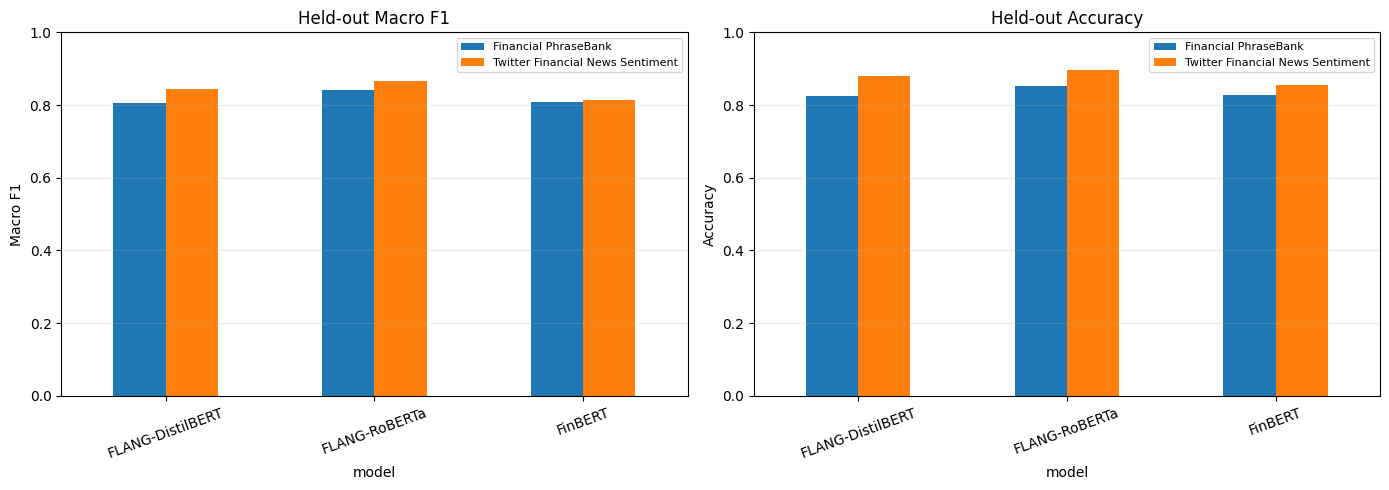

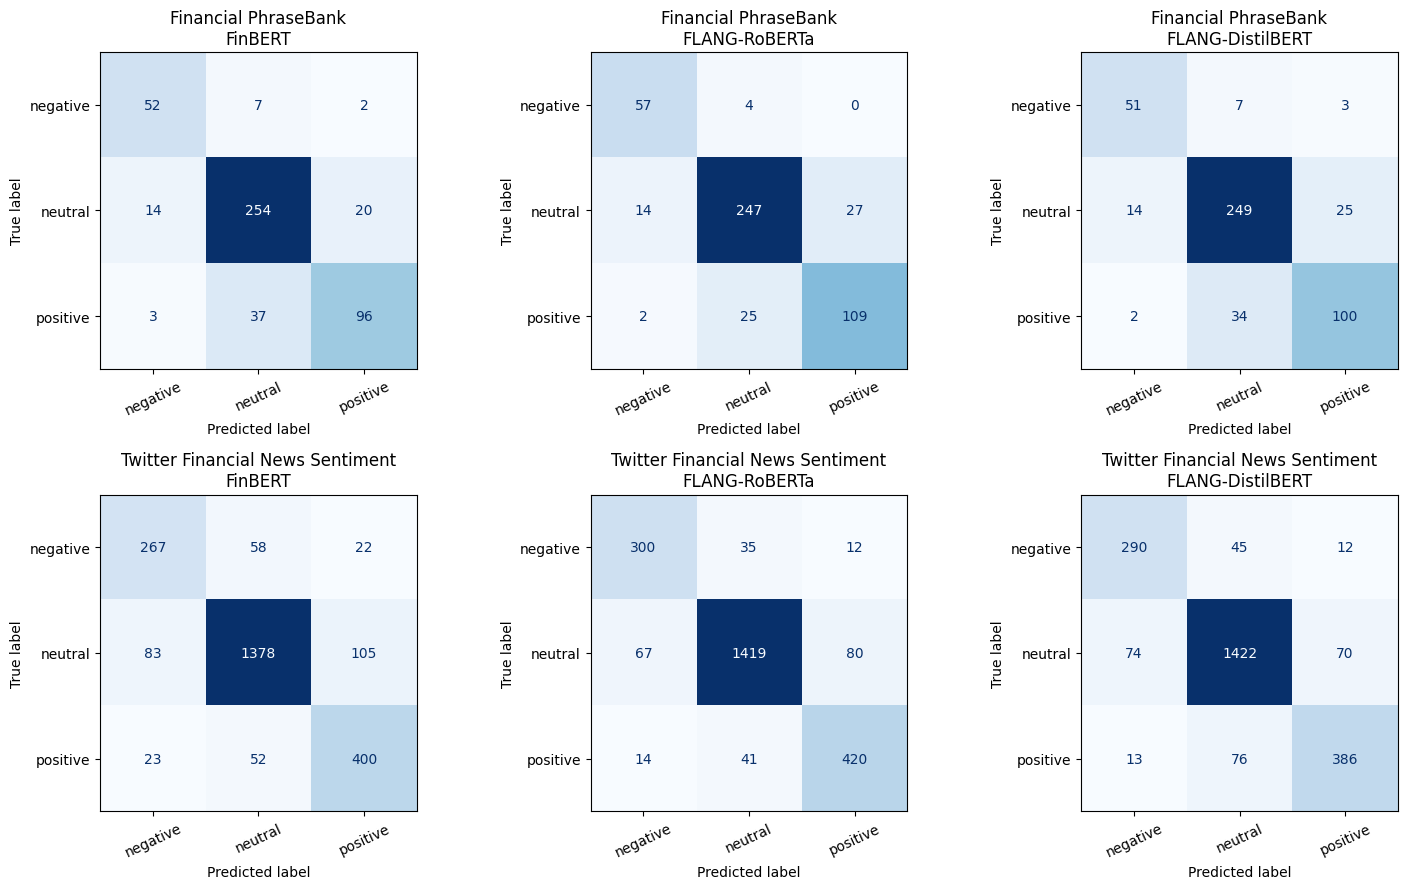

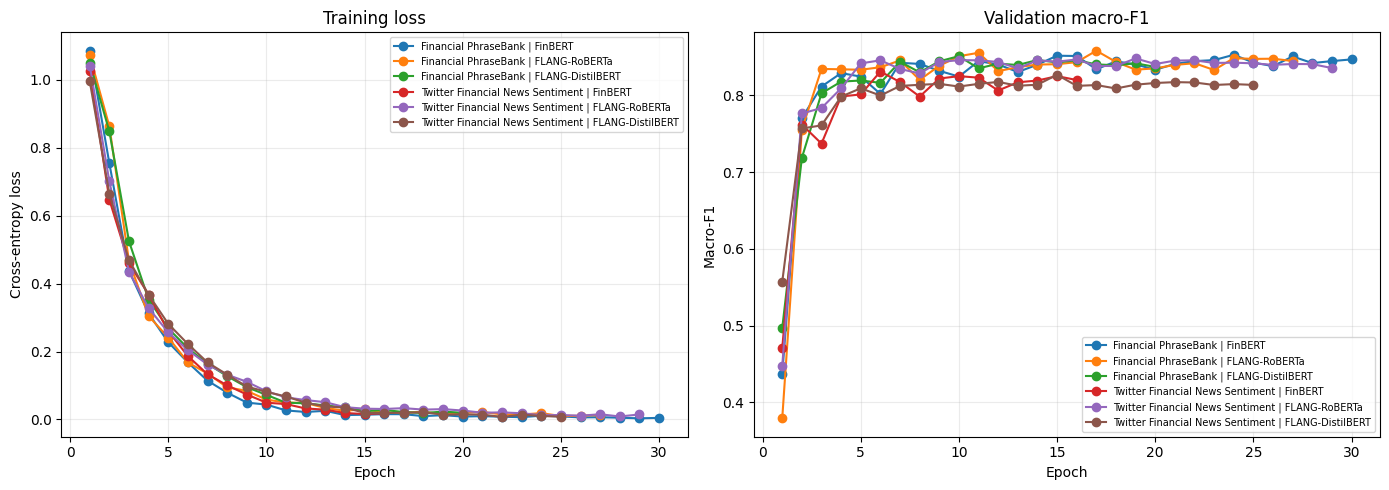

Plots saved to: /kaggle/working/financial_sentiment_classification


In [7]:
# Held-out macro-F1 and accuracy comparison.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric_name, title in zip(axes, ["macro_f1", "accuracy"], ["Held-out Macro F1", "Held-out Accuracy"]):
    pivot = results_df.pivot(index="model", columns="dataset", values=metric_name)
    pivot.plot(kind="bar", ax=ax, rot=20)
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.set_ylabel(metric_name.replace("_", " ").title())
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "classification_model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# Confusion matrices on each dataset's held-out test split.
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, dataset_name in enumerate(["Financial PhraseBank", "Twitter Financial News Sentiment"]):
    for col, model_label in enumerate(MODEL_CHECKPOINTS):
        y_true, y_pred = all_predictions[(dataset_name, model_label)]
        disp = ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=range(len(LABELS))), display_labels=LABELS)
        disp.plot(ax=axes[row, col], colorbar=False, cmap="Blues", values_format="d")
        axes[row, col].set_title(f"{dataset_name}\n{model_label}")
        axes[row, col].tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "classification_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

# Training loss and validation macro-F1 curves, separated by dataset.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for dataset_name in ["Financial PhraseBank", "Twitter Financial News Sentiment"]:
    for model_label in MODEL_CHECKPOINTS:
        hist = all_histories[(dataset_name, model_label)]
        axes[0].plot(hist["epoch"], hist["train_loss"], marker="o", label=f"{dataset_name} | {model_label}")
        axes[1].plot(hist["epoch"], hist["val_macro_f1"], marker="o", label=f"{dataset_name} | {model_label}")
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "classification_learning_curves.png", dpi=160, bbox_inches="tight")
plt.show()
print("Plots saved to:", OUTPUT_DIR)

## Reading the results

Use **macro-F1** as the primary comparison because the sentiment classes are imbalanced; review per-class precision/recall and confusion matrices to see which classes each model misses. PhraseBank results use a reproducible random split because this release has no official split. Twitter's provided validation partition is treated as the held-out test partition for this experiment. Do not tune hyperparameters against either final test set.